In [ ]:
import os
import sys
from pathlib import Path

# repo root (notebooks live in notebooks/)
_root = Path.cwd()
if not (_root / "pyproject.toml").exists():
    _root = _root.parent
os.chdir(_root)
_src = _root / "src"
if _src.is_dir() and str(_src) not in sys.path:
    sys.path.insert(0, str(_src))


In [2]:
import numpy as np

data = np.load('data/final_records.npy', allow_pickle=True)  # 'allow_pickle=True' is necessary if your .npy file contains dictionaries

# Initialize lists to hold the data
ecg_segments = []
ppg_segments = []
sbp_values = []
dbp_values = []

for record in data:
    ecg_segments.append(record['ecg'])
    ppg_segments.append(record['ppg'])
    sbp_values.append(record['true_sbp'])
    dbp_values.append(record['true_dbp'])

ecg_segments = np.array(ecg_segments)
ppg_segments = np.array(ppg_segments)
sbp_values = np.array(sbp_values)
dbp_values = np.array(dbp_values)

combined_segments = np.stack((ecg_segments, ppg_segments), axis=-1)  # Shape: (num_samples, segment_length, 2)

In [3]:
from sklearn.model_selection import train_test_split

# Combined segments and labels
X = combined_segments  # Shape: (num_samples, segment_length, num_channels)
y_sbp = sbp_values     # Shape: (num_samples,)
y_dbp = dbp_values     # Shape: (num_samples,)

# First split: 80% training, 20% temporary (validation + test)
X_train_temp, X_temp_sbp, y_train_sbp, y_temp_sbp = train_test_split(
    X, y_sbp, test_size=0.2, random_state=42, shuffle=True
)

X_train_temp, X_temp_dbp, y_train_dbp, y_temp_dbp = train_test_split(
    X, y_dbp, test_size=0.2, random_state=42, shuffle=True
)

# Second split: Split the 20% temporary set into 10% validation and 10% test
X_val_sbp, X_test_sbp, y_val_sbp, y_test_sbp = train_test_split(
    X_temp_sbp, y_temp_sbp, test_size=0.5, random_state=42, shuffle=True
)

X_val_dbp, X_test_dbp, y_val_dbp, y_test_dbp = train_test_split(
    X_temp_dbp, y_temp_dbp, test_size=0.5, random_state=42, shuffle=True
)

print("SBP Dataset:")
print(f"Training set size: {X_train_temp.shape[0]} samples")
print(f"Validation set size: {X_val_sbp.shape[0]} samples")
print(f"Test set size: {X_test_sbp.shape[0]} samples")

print("\nDBP Dataset:")
print(f"Training set size: {X_train_temp.shape[0]} samples")
print(f"Validation set size: {X_val_dbp.shape[0]} samples")
print(f"Test set size: {X_test_dbp.shape[0]} samples")

SBP Dataset:
Training set size: 129472 samples
Validation set size: 16184 samples
Test set size: 16184 samples

DBP Dataset:
Training set size: 129472 samples
Validation set size: 16184 samples
Test set size: 16184 samples


In [9]:
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Conv1D, MaxPooling1D, Bidirectional, LSTM, Dense, ReLU
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping

num_train_samples, segment_length, num_channels = X_train_temp.shape

# Define early stopping
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=500,
    restore_best_weights=True
)

# Get input shape
input_shape = (segment_length, num_channels)

In [5]:
def build_model(input_shape):
    model = Sequential()

    # Convolutional Layer 1
    model.add(Conv1D(filters=128, kernel_size=3, padding='same', input_shape=input_shape))
    model.add(ReLU())
    model.add(MaxPooling1D(pool_size=10, strides=2))

    # Convolutional Layer 2
    model.add(Conv1D(filters=128, kernel_size=3, padding='same'))
    model.add(ReLU())
    model.add(MaxPooling1D(pool_size=10, strides=2))

    # Convolutional Layer 3
    model.add(Conv1D(filters=128, kernel_size=3, padding='same'))
    model.add(ReLU())
    model.add(MaxPooling1D(pool_size=4, strides=2))

    # Bidirectional LSTM Layer 1
    model.add(Bidirectional(LSTM(units=128, return_sequences=True)))

    # Bidirectional LSTM Layer 2
    model.add(Bidirectional(LSTM(units=128)))

    # Output Layer
    model.add(Dense(1))  # For regression output (SBP or DBP)

    # Define the optimizer
    optimizer = Adam(learning_rate=0.01)

    # Compile the model
    model.compile(optimizer=optimizer, loss='mean_squared_error', metrics=['mae'])

    return model


Epoch 1/1000
1012/1012 [==============================] - 27s 23ms/step - loss: 250.1763 - mae: 10.2148 - val_loss: 121.5305 - val_mae: 8.5088
Epoch 2/1000
1012/1012 [==============================] - 23s 23ms/step - loss: 125.0212 - mae: 8.5113 - val_loss: 121.6238 - val_mae: 8.5171
Epoch 3/1000
1012/1012 [==============================] - 20s 20ms/step - loss: 125.1059 - mae: 8.5162 - val_loss: 121.5177 - val_mae: 8.5026
Epoch 4/1000
1012/1012 [==============================] - 18s 18ms/step - loss: 125.2779 - mae: 8.5246 - val_loss: 122.2580 - val_mae: 8.5128
Epoch 5/1000
1012/1012 [==============================] - 18s 18ms/step - loss: 125.3797 - mae: 8.5254 - val_loss: 122.2386 - val_mae: 8.5123
Epoch 6/1000
1012/1012 [==============================] - 18s 18ms/step - loss: 125.5324 - mae: 8.5307 - val_loss: 121.6149 - val_mae: 8.5008
Epoch 7/1000
1012/1012 [==============================] - 18s 18ms/step - loss: 125.6077 - mae: 8.5343 - val_loss: 121.5518 - val_mae: 8.5012
Epoch

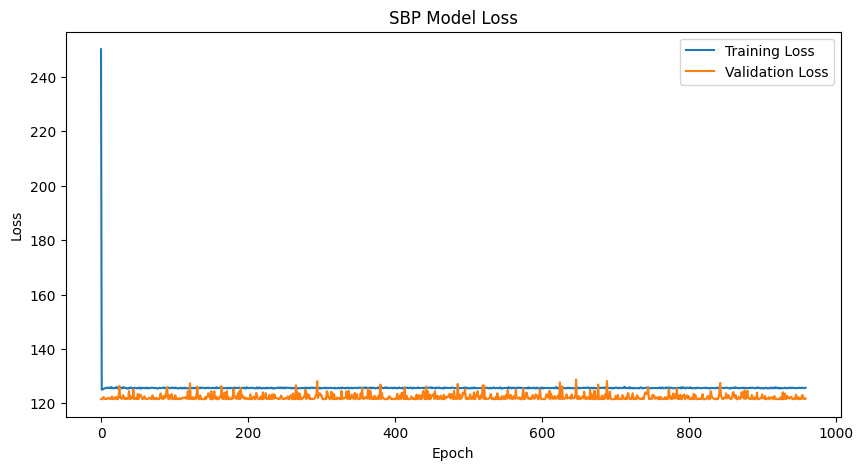

In [10]:
# Build and train SBP model
model_sbp = build_model(input_shape)
history_sbp = model_sbp.fit(
    X_train_temp,
    y_train_sbp,
    epochs=1000,
    batch_size=128,
    validation_data=(X_val_sbp, y_val_sbp),
    callbacks=[early_stopping],
    verbose=1
)

# Evaluate SBP model
test_loss_sbp, test_mae_sbp = model_sbp.evaluate(X_test_sbp, y_test_sbp)
print(f"SBP Model Test Loss: {test_loss_sbp}, Test MAE: {test_mae_sbp}")

from matplotlib import pyplot as plt

# Plot SBP model training history
plt.figure(figsize=(10, 5))
plt.plot(history_sbp.history['loss'], label='Training Loss')
plt.plot(history_sbp.history['val_loss'], label='Validation Loss')
plt.title('SBP Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
# Build and train DBP model
model_dbp = build_model(input_shape)
history_dbp = model_dbp.fit(
    X_train_temp,
    y_train_dbp,
    epochs=50,
    batch_size=128,
    validation_data=(X_val_dbp, y_val_dbp),
    callbacks=[early_stopping],
    verbose=1
)

# Evaluate DBP model
test_loss_dbp, test_mae_dbp = model_dbp.evaluate(X_test_dbp, y_test_dbp)
print(f"DBP Model Test Loss: {test_loss_dbp}, Test MAE: {test_mae_dbp}")

# Plot DBP model training history
plt.figure(figsize=(10, 5))
plt.plot(history_dbp.history['loss'], label='Training Loss')
plt.plot(history_dbp.history['val_loss'], label='Validation Loss')
plt.title('DBP Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()